In [36]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt
from scipy.optimize import minimize, approx_fprime

##### 1. Setup Data from handwritten **maths**

In [37]:
x = np.array([[1.0, 3.0],
              [4.0, 10.0]])
y = np.array([[5.0],
              [6.0]])

*   Setting initial parameters

In [38]:
m = np.array([[-1.0],
             [2.0]])
b = np.array([[1.0],
              [1.0]])
alpha = 0.01
num_iterations = 3
n = len(y) # n = 2

*   History tracking for visualization

In [39]:
m_history = [m.copy()]
b_history = [b.copy()]

initial_e = (np.dot(x, m) + b) - y
cost_history = [(1.0 / n) * np.sum(initial_e**2)]

print("=== Executing Manual Gradient Descent Loop ===")

=== Executing Manual Gradient Descent Loop ===


##### 2. Step-by-step Gradient Descent Loop

In [40]:
for i in range(1, num_iterations + 1):
    # 1. Predictions (Ŷ = Xm + b)
    y_hat = np.dot(x, m) + b

    # 2. Error Vector (e)
    error = y_hat - y

    # 3. Explicit Gradient computation
    dj_dm = (2.0 / n) * np.dot(x.T, error)
    dj_db = (2.0 / n) * np.sum(error)

    # 4. Parameter Updates
    m = m - alpha * dj_dm
    b = b - alpha * dj_db

    # 5. Cost function
    next_y_hat = np.dot(x, m) + b
    next_cost = (1.0 / n) * np.sum((next_y_hat - y)**2)

    # Record history
    m_history.append(m.copy())
    b_history.append(b.copy())
    cost_history.append(next_cost)

In [41]:

print(f"\n--- Iteration Update {i} ---")
print(f"Predictions Ŷ:\n{y_hat}")
print(f"Error Vector e:\n{error}")
print(f"Gradient wrt m (dj_dm):\n{dj_dm}")
print(f"Gradient wrt b (dj_db):\n{dj_db}")
print(f"Updated m:\n{m}")
print(f"Updated b:\n{b}")
print(f"Post_update Cost J: {next_cost:.4f}")


--- Iteration Update 3 ---
Predictions Ŷ:
[[3.1426]
 [7.4134]]
Error Vector e:
[[-1.8574]
 [ 1.4134]]
Gradient wrt m (dj_dm):
[[3.7962]
 [8.5618]]
Gradient wrt b (dj_db):
-0.4439999999999995
Updated m:
[[-1.369562]
 [ 1.095182]]
Updated b:
[[0.93624]
 [0.93624]]
Post_update Cost J: 2.3904


In [42]:
### Parameter Updates ###
m -= alpha * dj_dm
b -= alpha * dj_db

m_history.append(m.copy())
b_history.append(b.copy())

### Calculate final cost post-loop
final_cost = (1.0 / n) * np.sum((np.dot(x, m) + b - y)**2)
cost_history.append(final_cost)

##### 3. Scipy Minimization Verification

In [44]:
def compute_cost_flat(params):
  m_flat = params[0:2].reshape(2,1)
  b_flat = params[2:4].reshape(2,1)
  y_pred = np.dot(x, m_flat) + b_flat
  return (1.0 / n) * np.sum((y_pred - y)**2)

current_params =np.hstack((m.flatten(), b.flatten()))
epsilon = 1e-6

scipy_gradients = approx_fprime(current_params, compute_cost_flat, epsilon)

print("\n" + "="*50)
print("=== SciPy Explicit Derivative Verification ===")
print("="*50)
print(f"SciPy Estimated Derivative wrt m: {scipy_gradients[0:2]}")
print(f"SciPy Estimated Derivative wrt b: {scipy_gradients[2:4]}")


=== SciPy Explicit Derivative Verification ===
SciPy Estimated Derivative wrt m: [ -4.8132475 -13.2521615]
SciPy Estimated Derivative wrt b: [-2.4381515 -0.5937755]


##### 4. Matplotlib Visualization

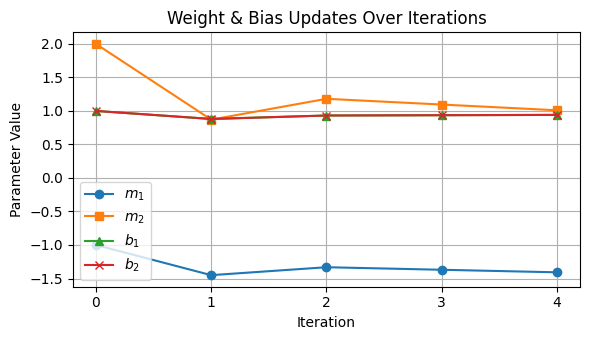

In [48]:
m_hist = np.array(m_history).squeeze()
b_hist = np.array(b_history).squeeze()
steps = np.arange(len(m_hist))

### Plot 1: Parameter updates over epochs
plt.figure(figsize=(6, 3.5))
plt.plot(steps, m_hist[:, 0], label='$m_1$', marker='o')
plt.plot(steps, m_hist[:, 1], label='$m_2$', marker='s')
plt.plot(steps, b_hist[:, 0], label='$b_1$', marker='^')
plt.plot(steps, b_hist[:, 1], label='$b_2$', marker='x')
plt.title('Weight & Bias Updates Over Iterations')
plt.xlabel('Iteration')
plt.ylabel('Parameter Value')
plt.xticks(steps)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

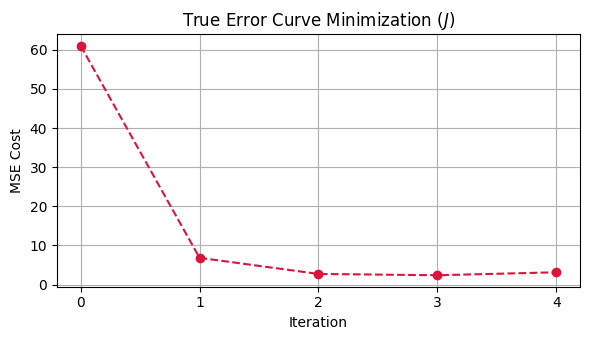

In [50]:
### Plot 2: Cost error trajectory
plt.figure(figsize=(6, 3.5))
plt.plot(steps, cost_history, color='crimson', marker='o', linestyle='--')
plt.title('True Error Curve Minimization ($J$)')
plt.xlabel('Iteration')
plt.ylabel('MSE Cost')
plt.xticks(steps)
plt.grid(True)
plt.tight_layout()
plt.show()